In [21]:
import numpy as np
import pandas as pd
import importlib
import matplotlib.pyplot as plt

from mpl_toolkits.mplot3d import Axes3D          # 3d graph
from mpl_toolkits.mplot3d import proj3d          # 3d graph


## Default setup for my figures ==================

plt.rcParams.update({'font.size': 9})
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
cm2in = 1/2.54
fig_format = '.png'
myColors = ['#626262', '#184e77', '#1A759F', '#34A0A4', '#76C893', '#B5E48C', '#EBF297']

# Import the Lifting-line solver libs ============

#import Solvers and functions:
import Libs.LL_Classes
import Libs.LL_ConstructObjs
import Libs.LL_PlotGeometry
import Libs.LL_Solvers
import Libs.LL_MAIN

## Reload files:
importlib.reload(Libs.LL_Classes);
importlib.reload(Libs.LL_ConstructObjs);
importlib.reload(Libs.LL_PlotGeometry);
importlib.reload(Libs.LL_Solvers);
importlib.reload(Libs.LL_MAIN);


## These are the list of functions for this project. They are here only for reference.
from Libs.LL_Classes       import blade
from Libs.LL_Classes       import bladePanel
from Libs.LL_Classes       import trailingVortex
from Libs.LL_Classes       import solutionVector
from Libs.LL_ConstructObjs import construstGeometry
from Libs.LL_ConstructObjs import createRadius
from Libs.LL_ConstructObjs import loadBladeElement
from Libs.LL_ConstructObjs import createAirfoils
from Libs.LL_PlotGeometry  import createFigure
from Libs.LL_PlotGeometry  import plotRotor
from Libs.LL_PlotGeometry  import plotTrailingVortexes
from Libs.LL_MAIN          import liftingLineSolver

## 1. Single Panel ##

Done.
[0.02937709 0.0451967  0.05393727 0.0564862  0.05393727 0.0451967
 0.02937709]


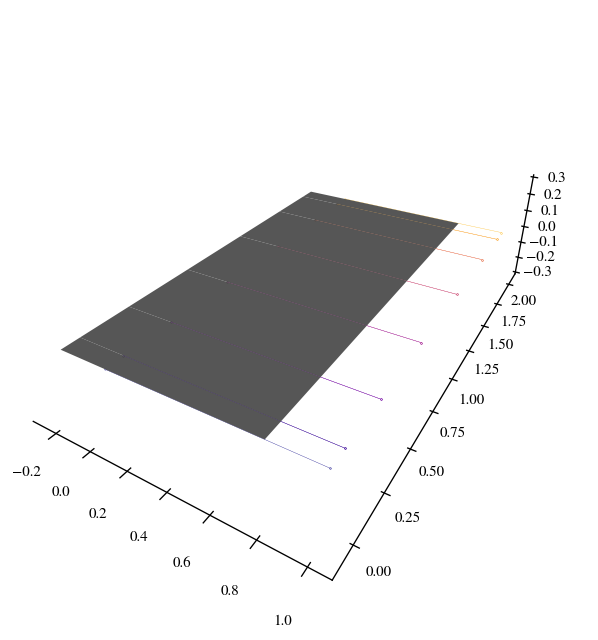

In [22]:
nb    = 1       # number of blades
ndt   = 1       #  number of time-steps for wake
ncp   = 7       # number of panels (control points) in each blade
R     = 2       # radius of the rotor, m
Rroot = 0       # root radius of the rotor, m
TSR   = 0       # tip speed ratio
a     = 1/3     # induction factor
Omega = 0       # Rotor's rotational speed, rad/s
dt    = 0.5     # time-steep for vortex sheeding, s
Uwind = 1       # x-direction wind speed, m/s
airfoil = './Resources/DU95W180.csv'
ChordCoefs = [1, 0, 0]   # ChordCoefs = [ca, cb, cc], # Chord = ca*(1 - cb*(r/R) ) + cc
TwistCoefs = [-90, 0, 0] # TwistCoefs = [ta, tb, tc], # Twist = ta*(1 - tb*(r/R) ) + tc


## Seed control points along radius ================= #

method = 'cosine' # 'linear' or 'cosine'
r, dr = createRadius(Rroot, R, ncp, method) # pointing to the control points

##  Construct objects =============================== #
bladepanels, trailingVortexes, mySolutionVector = construstGeometry(ChordCoefs, TwistCoefs, r, dr, dt, Uwind, Omega, nb, ncp, ndt)                                         


##  Plot figures =============================== #

ax = createFigure()
plotRotor(ax, bladepanels)                         ## Show rotor's design:
plotTrailingVortexes(ax, trailingVortexes, ncp*nb) ## Plot trailing vortexes
ax.set_zlim(-0.3, 0.3) 
ax.set_box_aspect([ub - lb for lb, ub in (getattr(ax, f'get_{a}lim')() for a in 'xyz')])


## We are not interested in this solution. The template follows below, nonetheless:
solution = liftingLineSolver(mySolutionVector, bladepanels, trailingVortexes, Uwind, Omega, R, airfoil)

print(solution.Gamma)


## 2. Flat-wing in steady flow ##

Done.


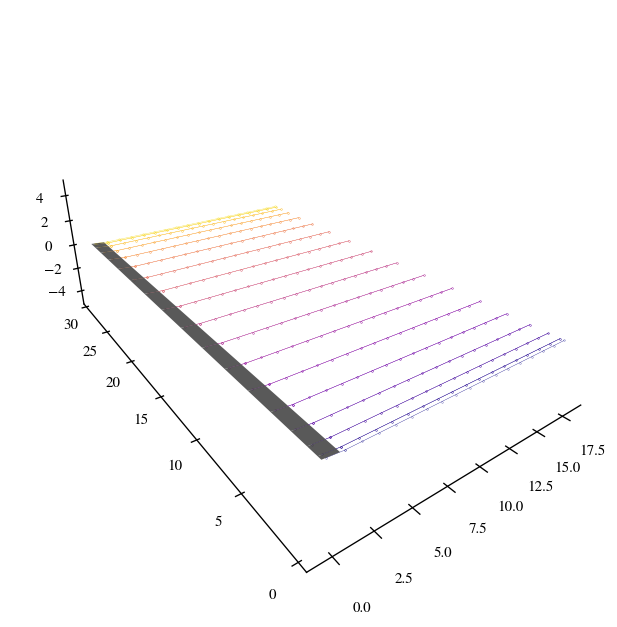

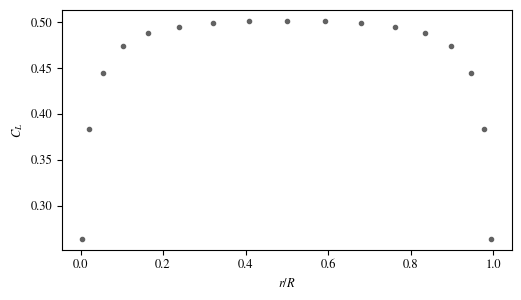

In [23]:
nb    = 1       # number of blades
ndt   = 17      #  number of time-steps for wake
ncp   = 17      # number of panels (control points) in each blade
R     = 30      # radius of the rotor, m
Rroot = 0       # root radius of the rotor, m
TSR   = 0       # tip speed ratio
a     = 1/3     # induction factor
Omega = 0       # Rotor's rotational speed, rad/s
dt    = 0.1     # time-steep for vortex sheeding, s
Uwind = 10      # x-wise wake speed, m/s
ChordCoefs = [1, 0, 0]   # ChordCoefs = [ca, cb, cc], # Chord = ca*(1 - cb*(r/R) ) + cc
TwistCoefs = [-85, 0, 0] # TwistCoefs = [ta, tb, tc], # Twist = ta*(1 - tb*(r/R) ) + tc
airfoil = './Resources/TwoPImodel.csv'

## Seed control points along radius ================= #
method = 'cosine' # 'linear' or 'cosine'
r, dr = createRadius(Rroot, R, ncp, method) # pointing to the control points


##  Construct objects =============================== #
bladepanels, trailingVortexes, mySolutionVector = construstGeometry(ChordCoefs, TwistCoefs, r, dr, dt, Uwind,Omega, nb, ncp, ndt)                                             


##  Plot figures ==================================== #
ax = createFigure()
plotRotor(ax, bladepanels)                         ## Show rotor's design:
plotTrailingVortexes(ax, trailingVortexes, ncp*nb) ## Plot trailing vortexes

ax.set_xlim(-1, Uwind*dt*ndt+2) 
ax.set_ylim(0, 30) 
ax.set_zlim(-5, 5)
ax.set_box_aspect([ub - lb for lb, ub in (getattr(ax, f'get_{a}lim')() for a in 'xyz')])
ax.view_init(25, -125, 0)


##  Solve LL model ================================== #


# Use a "2 pi sin(alpha) " lift-curve model:
polar_alpha = np.linspace(-30,30,100) # angle of attack, deg
polar_cd    = np.zeros_like(polar_alpha)
polar_cl    = 2*np.pi*np.sin( polar_alpha * np.pi/180 ) # CL = 2 pi sin(AoA)

solution = liftingLineSolver(mySolutionVector, bladepanels, trailingVortexes, Uwind, Omega, R, airfoil)

##  Plot circulation over airfoil =================== #
normForces = np.zeros(ncp)
for i, ipanel in enumerate(bladepanels):
    normForces[i] = 0.5 * Uwind**2 * ipanel.chord

fig, ax = plt.subplots(figsize=(6,3))
plt.subplots_adjust(left=0.15, bottom=0.15, right=0.9, top=0.95)

ax.plot(solution.r_R, solution.Ftan/normForces, '.', color=myColors[0], linewidth=2, label='$a$')
ax.set_xlabel('$r/R$')
ax.set_ylabel('$C_L$');

## 3. Single-blade rotor ##

* test influence of number of blade sections

Number of rotations: 10.19
Normalized time-step size: 0.03
Done.
CT, CP: 0.2440, 0.2091


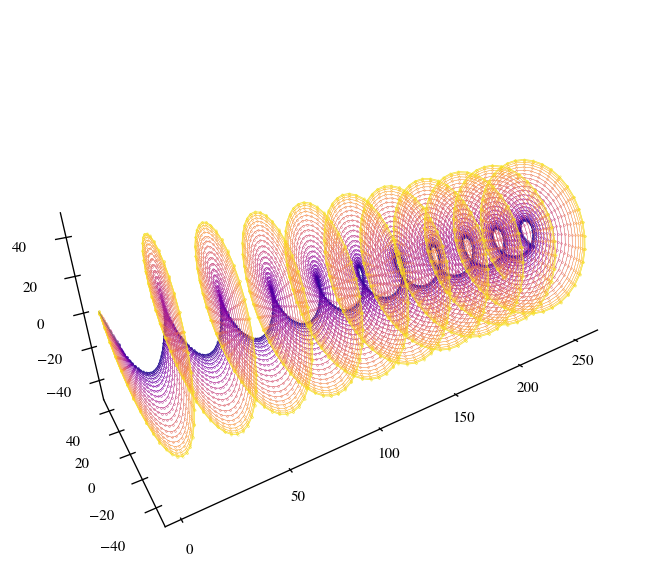

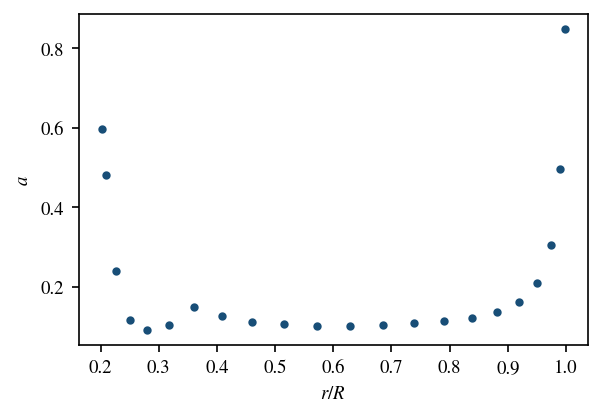

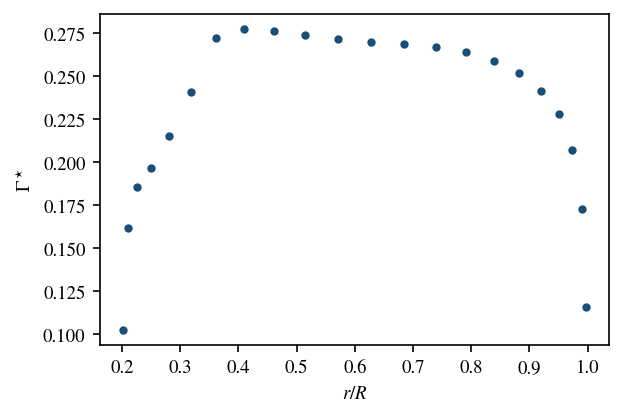

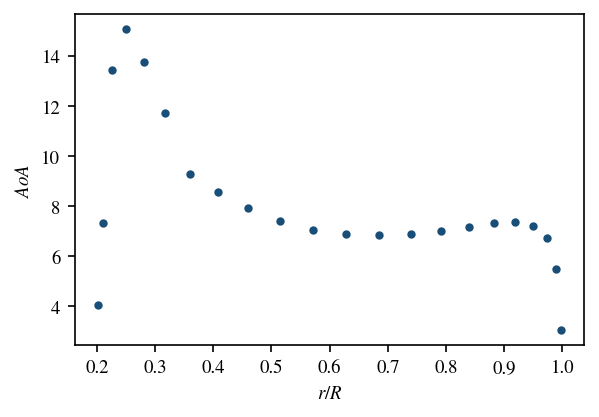

In [24]:
nb    = 1       # number of blades
ndt   = 400     # number of time-steps for wake
ncp   = 22      # number of panels (control points) in each blade
R     = 50      # radius of the rotor, m
Rroot = 10      # root radius of the rotor, m
TSR   = 8       # tip speed ratio
a     = 1/3     # induction factor
dt    = 0.1    # time-steep for vortex sheeding, s
Uwind = 10     # x-direction wake speed, m/s
airfoil = './Resources/DU95W180.csv'
ChordCoefs = [3,   1, 1]    # ChordCoefs = [ca, cb, cc], # Chord = ca*(1 - cb*(r/R) ) + cc
TwistCoefs = [-14, 1, 2]    # TwistCoefs = [ta, tb, tc], # Twist = ta*(1 - tb*(r/R) ) + tc
Omega = TSR*Uwind/R      # Rotor's rotational speed, rad/s


## Get some useful insights about the current benchmark:
rotationPeriod = ( 1 / (Omega / (2*np.pi) ) )
totalWakeTime  = dt*ndt
wakeSpeed  = Uwind*(1-a)
wakeXLength = wakeSpeed * totalWakeTime
normDt     = dt / rotationPeriod
numRot     = totalWakeTime / rotationPeriod
print('=========================================')
print('Number of rotations: %0.2f' % numRot )
print('Normalized time-step size: %0.2f' % normDt )
print('=========================================')


## Seed control points along radius ================= #
method = 'cosine' # 'linear' or 'cosine'
r, dr = createRadius(Rroot, R, ncp, method) # pointing to the control points


##  Construct objects =============================== #
bladepanels, trailingVortexes, mySolutionVector = construstGeometry(ChordCoefs, TwistCoefs, r, dr, dt, Uwind*(1-a), -Omega, nb, ncp, ndt)

##  Show geometry =================================== #
ax = createFigure()

plotRotor(ax, bladepanels)                         ## Show rotor's design:
plotTrailingVortexes(ax, trailingVortexes, ncp*nb) ## Plot trailing vortexes
ax.set_xlim(-1, wakeXLength) 
ax.set_ylim(-50, 50) 
ax.set_zlim(-50, 50)
ax.set_box_aspect([ub - lb for lb, ub in (getattr(ax, f'get_{a}lim')() for a in 'xyz')])
ax.view_init(25, -125, 0)
plt.savefig("./Images/SingleBlade"+fig_format, dpi=300)

##  Plot results ==================================== #
LLM = liftingLineSolver(mySolutionVector, bladepanels, trailingVortexes, Uwind, Omega, R, airfoil)

normGamma = normGamma = Uwind**2 * np.pi / ( Omega * nb)

fig, ax = plt.subplots(figsize=(11.5*cm2in, 7*cm2in), dpi=150)
plt.subplots_adjust(left=0.15, bottom=0.15, right=0.9, top=0.95)
ax.plot(LLM.r_R, LLM.a, 'o', markersize=3., color=myColors[1])
ax.set_xlabel(r'$r/R$')
ax.set_ylabel(r'$a$')


fig, ax = plt.subplots(figsize=(11.5*cm2in, 7*cm2in), dpi=150)
plt.subplots_adjust(left=0.15, bottom=0.15, right=0.9, top=0.95)
ax.plot(LLM.r_R, LLM.Gamma/normGamma, 'o', markersize=3., color=myColors[1])
ax.set_xlabel(r'$r/R$')
ax.set_ylabel(r'$\Gamma^\star$');

fig, ax = plt.subplots(figsize=(11.5*cm2in, 7*cm2in), dpi=150)
plt.subplots_adjust(left=0.15, bottom=0.15, right=0.9, top=0.95)
ax.plot(LLM.r_R, LLM.alpha, 'o', markersize=3., color=myColors[1])
ax.set_xlabel(r'$r/R$')
ax.set_ylabel(r'$AoA$');


forceNorm = 0.5 * Uwind**2 * (np.pi * R ** 2)


CT = np.sum( LLM.Fnorm[0:ncp] * dr  ) / forceNorm  * nb
CP = np.sum( LLM.Ftan[0:ncp]  * dr * (LLM.r_R[0:ncp] * Omega * R) ) / (forceNorm * Uwind) * nb
print('CT, CP: %0.4f, %0.4f' % (CT, CP) )

## 4. Three-blades rotor ##

Number of rotations: 10.19
Normalized time-step size: 0.03
Done.


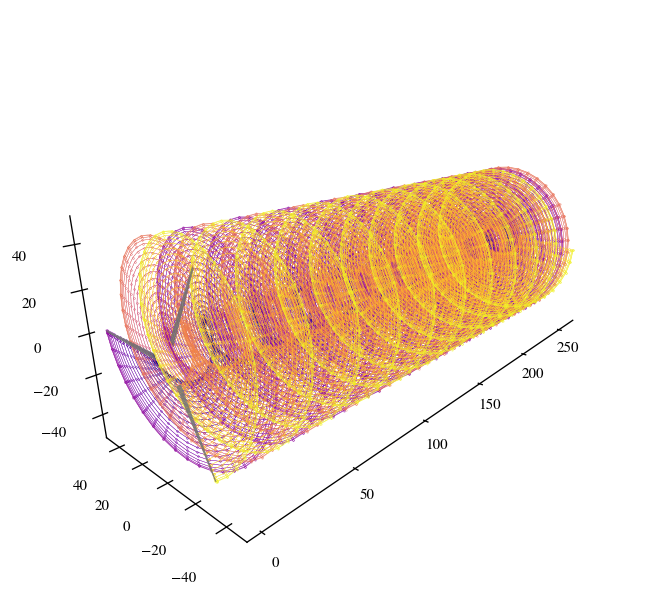

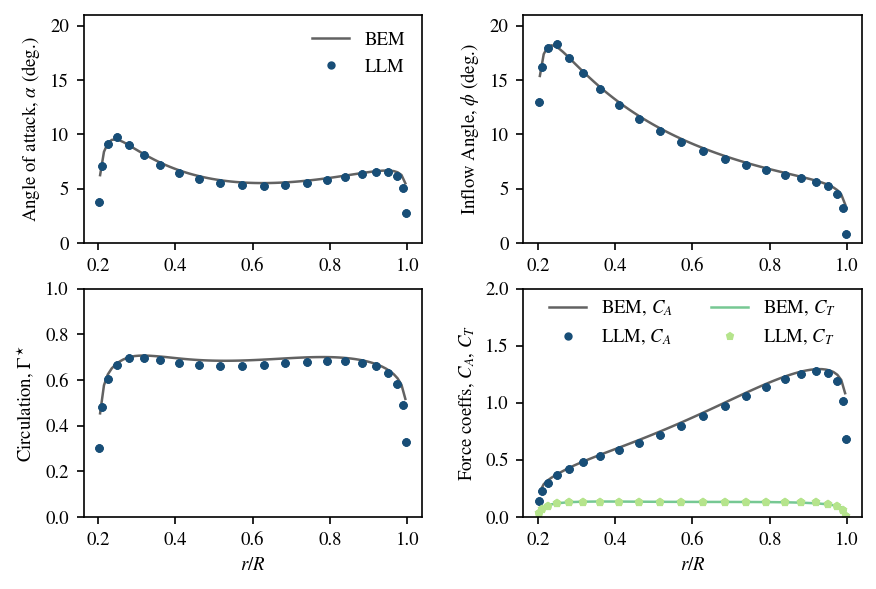

In [25]:
nb    = 3       # number of blades
ncp   = 22      # number of panels (control points) in each blade
R     = 50      # radius of the rotor, m
Rroot = 10      # root radius of the rotor, m
TSR   = 8       # tip speed ratio
a     = 1/3     # induction factor
dt    = 0.1     # time-steep for vortex sheeding, s
ndt   = 400     #  number of time-steps for wake
Uwind = 10      # x-direction wake speed, m/s
airfoil = './Resources/DU95W180.csv'
ChordCoefs = [3,   1, 1]    # ChordCoefs = [ca, cb, cc], # Chord = ca*(1 - cb*(r/R) ) + cc
TwistCoefs = [-14, 1, 2]    # TwistCoefs = [ta, tb, tc], # Twist = ta*(1 - tb*(r/R) ) + tc
Omega = TSR*Uwind/R      # Rotor's rotational speed, rad/s


rotationPeriod = ( 1 / (Omega / (2*np.pi) ) )
totalWakeTime  = dt*ndt
wakeSpeed  = Uwind*(1-a)
wakeXLength = wakeSpeed * totalWakeTime
normDt     = dt / rotationPeriod
numRot     = totalWakeTime / rotationPeriod
print('=========================================')
print('Number of rotations: %0.2f' % numRot )
print('Normalized time-step size: %0.2f' % normDt )
print('=========================================')


## Seed control points along radius ================= #
method = 'cosine' # 'linear' or 'cosine'
r, dr = createRadius(Rroot, R, ncp, method) # pointing to the control points


##  Construct objects =============================== #
bladepanels, trailingVortexes, mySolutionVector = construstGeometry(ChordCoefs, TwistCoefs, r, dr, dt, Uwind*(1-a), -Omega, nb, ncp, ndt)


##  Show geometry =================================== #
ax = createFigure()
plotTrailingVortexes(ax, trailingVortexes, ncp*nb) ## Plot trailing vortexes
plotRotor(ax, bladepanels)                         ## Show rotor's design:
ax.set_xlim(-1, wakeXLength) 
ax.set_ylim(-50, 50) 
ax.set_zlim(-50, 50)
ax.set_box_aspect([ub - lb for lb, ub in (getattr(ax, f'get_{a}lim')() for a in 'xyz')])
ax.view_init(18, -140, 0)
plt.savefig("./Images/ThreeBlades2"+fig_format, bbox_inches='tight', dpi=300, transparent=True)

##  Solve system ==================================== #
# LLM data contains arrays of: ['a' , 'aline', 'r_R', 'Fnorm' , 'Ftan', 'Gamma' 'alpha', 'inflowAngle']
LLM = liftingLineSolver(mySolutionVector, bladepanels, trailingVortexes, Uwind, Omega, R, airfoil)


# BEM data contains arrays of: ['a' , 'aline', 'r_R', 'Fnorm' , 'Ftan', 'Gamma', 'inflowAngle', 'alpha', 'annuliAreas', 'lift', 'drag']
BEM = pd.read_csv('./BEMdata.csv', sep=',')


##  Angle of Attack ========================= #
fig, axs = plt.subplots(2,2,figsize=(15.5*cm2in, 10*cm2in), dpi=150)
plt.subplots_adjust(left=0.1, bottom=0.1, right=0.95, top=0.95, wspace=0.3)
axs[0,0].plot(BEM.r_R, BEM.alpha, '-', linewidth=1.2, color=myColors[0], label='BEM')
axs[0,0].plot(LLM.r_R, LLM.alpha, 'o', markersize=3., color=myColors[1], label='LLM')
axs[0,0].set_ylabel(r'Angle of attack, $ \alpha $ (deg.)')
axs[0,0].set_ylim(0, 21)
axs[0,0].legend(frameon=False)


##  Inflow Angle ========================= #
axs[0,1].plot(BEM.r_R, BEM.inflowAngle, '-', linewidth=1.2, color=myColors[0], label='BEM')
axs[0,1].plot(LLM.r_R, LLM.inflowAngle, 'o', markersize=3., color=myColors[1], label='LLM')
axs[0,1].set_ylim(0, 21)
axs[0,1].set_ylabel(r'Inflow Angle, $ \phi $ (deg.)')


##  Circulation ========================= #
normGamma = normGamma = Uwind**2 * np.pi / ( Omega * nb)
axs[1,0].plot(BEM.r_R, BEM.Gamma/normGamma, '-', linewidth=1.2, color=myColors[0], label='BEM')
axs[1,0].plot(LLM.r_R, LLM.Gamma/normGamma, 'o', markersize=3., color=myColors[1], label='LLM')
axs[1,0].set_xlabel(r'$r/R$')
axs[1,0].set_ylim(0, 1)
axs[1,0].set_ylabel(r'Circulation, $ \Gamma^\star $')


##  Axial/Normal loading ========================= #
forceNorm = 0.5 * Uwind**2 * R
axs[1,1].plot(BEM.r_R, BEM.Fnorm/forceNorm, '-', linewidth=1.2, color=myColors[0], label='BEM, $C_A$')
axs[1,1].plot(LLM.r_R, LLM.Fnorm/forceNorm, 'o', markersize=3., color=myColors[1], label='LLM, $C_A$')
axs[1,1].plot(BEM.r_R, BEM.Ftan/forceNorm,  '-', linewidth=1.2, color=myColors[4], label='BEM, $C_T$')
axs[1,1].plot(LLM.r_R, LLM.Ftan/forceNorm,  'p', markersize=3., color=myColors[5], label='LLM, $C_T$')
axs[1,1].set_ylim(0, 2)
axs[1,1].set_ylabel(r'Force coeffs, $C_A$, $C_T$')
axs[1,1].set_xlabel(r'$r/R$')
axs[1,1].legend(ncols=2, loc='center', bbox_to_anchor=(0.5, 0.85), frameon=False)


plt.savefig("./Images/LLM_Solutions"+fig_format, dpi=300)

## Determine total thrust for increasing TSR ##

Number of time-steps: 100
time-step size: 0.400
Done.
Number of time-steps: 125
time-step size: 0.320
Done.
Number of time-steps: 149
time-step size: 0.267
Done.
Number of time-steps: 174
time-step size: 0.229
Done.
Number of time-steps: 200
time-step size: 0.200
Done.
Number of time-steps: 225
time-step size: 0.178
Done.
Number of time-steps: 250
time-step size: 0.160
Done.
Number of time-steps: 275
time-step size: 0.145
Done.
Number of time-steps: 299
time-step size: 0.133
Done.
Number of time-steps: 325
time-step size: 0.123
Done.
Number of time-steps: 349
time-step size: 0.114
Done.
Number of time-steps: 375
time-step size: 0.107
Done.
Number of time-steps: 400
time-step size: 0.100
Done.


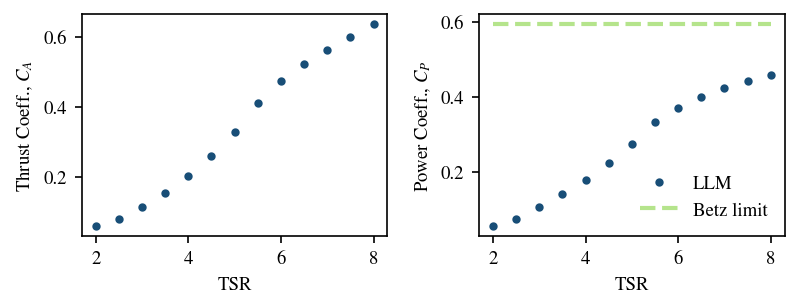

In [26]:
nb    = 3       # number of blades
ncp   = 22      # number of panels (control points) in each blade
R     = 50      # radius of the rotor, m
Rroot = 10      # root radius of the rotor, m
TSR0  = 8       # tip speed ratio
a     = 1/3     # induction factor
dt0   = 0.1     # time-steep for vortex sheeding, s
ndt0   = 400    #  number of time-steps for wake
Uwind = 10      # x-direction wake speed, m/s
airfoil = './Resources/DU95W180.csv'
ChordCoefs = [3,   1, 1]    # ChordCoefs = [ca, cb, cc], # Chord = ca*(1 - cb*(r/R) ) + cc
TwistCoefs = [-14, 1, 2]    # TwistCoefs = [ta, tb, tc], # Twist = ta*(1 - tb*(r/R) ) + tc
Omega0 = TSR0*Uwind/R      # Rotor's rotational speed, rad/s


## Seed control points along radius ================= #
method = 'cosine' # 'linear' or 'cosine'
r, dr = createRadius(Rroot, R, ncp, method) # pointing to the control points


##  Construct objects =============================== #

forceNorm = 0.5 * Uwind**2 * (np.pi * R ** 2)


TSR   = np.linspace(2,8,num=13)     # tip speed ratio
Omega = TSR*Uwind/R                 # Rotor's rotational speed, rad/s
CA = np.zeros_like(TSR)             # total thrust force coefficient
CP = np.zeros_like(TSR)             # total power coeff.

print('=========================================')

for i, omg in enumerate(Omega):

    ndt = int( omg/Omega0 * ndt0 ) # increase number of data points
    dt  =  Omega0/omg * dt0
    
    print('Number of time-steps: %0.0f' % ndt )
    print('time-step size: %0.3f' % dt )

    bladepanels, trailingVortexes, mySolutionVector = construstGeometry(ChordCoefs, TwistCoefs, r, dr, dt, Uwind*(1-a), -omg, nb, ncp, ndt)
     
    LLM = liftingLineSolver(mySolutionVector, bladepanels, trailingVortexes, Uwind, omg, R, airfoil)

    CA[i] = np.sum( LLM.Fnorm[0:ncp] * dr  ) / forceNorm  * nb
    CP[i] = np.sum( LLM.Ftan[0:ncp]  * dr * (LLM.r_R[0:ncp] * omg * R) ) / (forceNorm * Uwind) * nb

print('=========================================')


# TotalPower = CP * (forceNorm * Uwind) * nb / (omg * R)

##  Show results ========================= #
fig, axs = plt.subplots(1, 2, figsize=(14*cm2in, 5*cm2in), dpi=150)
plt.subplots_adjust(left=0.1, bottom=0.2, right=0.95, top=0.95, wspace=0.3)

axs[0].plot(TSR, CA, 'o', markersize=3., color=myColors[1], label='LLM')
axs[0].set_ylabel(r'Thrust Coeff., $C_A$')
axs[0].set_xlabel(r'TSR')

axs[1].plot(TSR, CP, 'o', markersize=3., color=myColors[1], label='LLM')
axs[1].plot([2,8], [16/27,16/27], '--', color=myColors[5], linewidth=2, label=r'Betz limit')
axs[1].set_ylabel(r'Power Coeff., $C_P$')
axs[1].set_xlabel(r'TSR')
axs[1].legend(frameon=False)

plt.savefig("./Images/LLM_Efficiency_vs_TSR"+fig_format, dpi=300)

## Test sensitivity to convection speed ##

In [27]:
nb    = 3       # number of blades
ncp   = 22      # number of panels (control points) in each blade
R     = 50      # radius of the rotor, m
Rroot = 10      # root radius of the rotor, m
TSR  = 8       # tip speed ratio
a    = 1/3     # induction factor
dt   = 0.1     # time-steep for vortex sheeding, s
ndt  = 400     #  number of time-steps for wake
Uwind = 10      # x-direction wake speed, m/s
airfoil = './Resources/DU95W180.csv'
ChordCoefs = [3,   1, 1]    # ChordCoefs = [ca, cb, cc], # Chord = ca*(1 - cb*(r/R) ) + cc
TwistCoefs = [-14, 1, 2]    # TwistCoefs = [ta, tb, tc], # Twist = ta*(1 - tb*(r/R) ) + tc
Omega = TSR*Uwind/R      # Rotor's rotational speed, rad/s


# BEM data contains arrays of: ['a' , 'aline', 'r_R', 'Fnorm' , 'Ftan', 'Gamma', 'inflowAngle', 'alpha', 'annuliAreas', 'lift', 'drag']
BEM = pd.read_csv('./BEMdata.csv', sep=',')

## Seed control points along radius ================= #
method = 'cosine' # 'linear' or 'cosine'
r, dr = createRadius(Rroot, R, ncp, method) # pointing to the control points


fig, axs = plt.subplots(1, 2, figsize=(14*cm2in, 5*cm2in), dpi=150)
plt.subplots_adjust(left=0.1, bottom=0.2, right=0.95, top=0.95, wspace=0.3)


awake  = np.arange(0, 3/3, step=1/3)     # wake-convection induction factor

for i, ai in enumerate(awake):

    # OBSERVATION: TSR is not kept constant!!!

    bladepanels, trailingVortexes, mySolutionVector = construstGeometry(ChordCoefs, TwistCoefs, r, dr, dt, Uwind*(1-ai), -Omega, nb, ncp, ndt)
   
    LLM = liftingLineSolver(mySolutionVector, bladepanels, trailingVortexes, Uwind, Omega, R, airfoil)

    ##  Plot Circulation ========================= #
    normGamma = Uwind**2 * np.pi / ( Omega * nb)
    axs[0].plot(LLM.r_R, LLM.Gamma/normGamma, 'o', markersize=3., color=myColors[2*i] )

    ##  Axial/Normal loading ========================= #
    forceNorm = 0.5 * Uwind**2 * R
    axs[1].plot(LLM.r_R, LLM.a, 'o', markersize=3., color=myColors[2*i], label=r'$a_w=%0.2f$' % ai )
    

axs[0].plot(BEM.r_R, BEM.Gamma/normGamma, '-', linewidth=1.2, color=myColors[0] )
axs[0].set_xlabel(r'$r/R$')
axs[0].set_ylabel(r'Ciculation, $ \Gamma^\star $')


axs[1].plot(BEM.r_R, BEM.a, '-', linewidth=1.2, color=myColors[0], label=r'BEM' )
axs[1].set_ylabel(r'Axial induction, $a$')
axs[1].set_xlabel(r'$r/R$')
axs[1].legend(ncols=2, loc='center', bbox_to_anchor=(0.5, 0.85), frameon=False)

plt.savefig("./Images/LLM_Effects_of_Wake_Induction"+fig_format, dpi=300)

## Sensitivity to discretization of the wake ##

Number of time-steps: 50
time-step size: 0.785
Done.
Number of time-steps: 100
time-step size: 0.393
Done.
Number of time-steps: 200
time-step size: 0.196
Done.


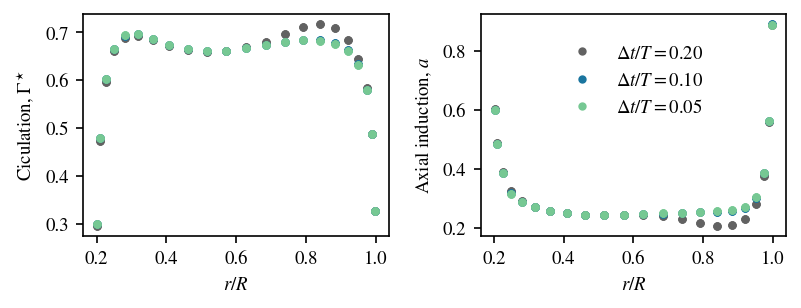

In [ ]:
nb    = 3       # number of blades
ncp   = 22      # number of panels (control points) in each blade
R     = 50      # radius of the rotor, m
Rroot = 10      # root radius of the rotor, m
TSR  = 8       # tip speed ratio
a     = 1/3     # induction factor
dt0   = 0.1     # time-steep for vortex sheeding, s
ndt0   = 400    #  number of time-steps for wake
Uwind = 10      # x-direction wake speed, m/s
airfoil = './Resources/DU95W180.csv'
ChordCoefs = [3,   1, 1]    # ChordCoefs = [ca, cb, cc], # Chord = ca*(1 - cb*(r/R) ) + cc
TwistCoefs = [-14, 1, 2]    # TwistCoefs = [ta, tb, tc], # Twist = ta*(1 - tb*(r/R) ) + tc
Omega = TSR*Uwind/R      # Rotor's rotational speed, rad/s

forceNorm = 0.5 * Uwind**2 * (np.pi * R ** 2)

## Seed control points along radius ================= #
method = 'cosine' # 'linear' or 'cosine'
r, dr = createRadius(Rroot, R, ncp, method) # pointing to the control points


## How many grid-points there are in 1 rotation
rotationPeriod = ( 1 / (Omega / (2*np.pi) ) )
npointsPerT0  = rotationPeriod/dt0
numberOfRotations = 10


fig, axs = plt.subplots(1, 2, figsize=(14*cm2in, 5*cm2in), dpi=150)
plt.subplots_adjust(left=0.1, bottom=0.2, right=0.95, top=0.95, wspace=0.3)

print('=========================================')

pointsPerRotation = np.array([5,10,20])     # tip speed ratio

for i, nPointsPerT in enumerate(pointsPerRotation):

    ndt =  int( numberOfRotations * nPointsPerT ) # increase number of data points
    dt  =  rotationPeriod * numberOfRotations / ndt
    
    print('Number of time-steps: %0.0f' % ndt )
    print('time-step size: %0.3f' % dt )

    bladepanels, trailingVortexes, mySolutionVector = construstGeometry(ChordCoefs, TwistCoefs, r, dr, dt, Uwind*(1-a), -Omega, nb, ncp, ndt)
     
    LLM = liftingLineSolver(mySolutionVector, bladepanels, trailingVortexes, Uwind, Omega, R, airfoil)

    ##  Plot Circulation ========================= #
    normGamma = Uwind**2 * np.pi / ( Omega * nb)
    axs[0].plot(LLM.r_R, LLM.Gamma/normGamma, 'o', markersize=3., color=myColors[2*i] )

    ##  Axial/Normal loading ========================= #
    forceNorm = 0.5 * Uwind**2 * R
    dt_norm = 1/nPointsPerT
    axs[1].plot(LLM.r_R, LLM.a, 'o', markersize=3., color=myColors[2*i], label=r'$\Delta t/T=%0.2f$' % dt_norm )

print('=========================================')

axs[0].set_xlabel(r'$r/R$')
axs[0].set_ylabel(r'Ciculation, $ \Gamma^\star $')


axs[1].set_ylabel(r'Axial induction, $a$')
axs[1].set_xlabel(r'$r/R$')
axs[1].legend(ncols=1, loc='center', bbox_to_anchor=(0.5, 0.7), frameon=False)

plt.savefig("./Images/LLM_Effects_of_WakeDiscretization"+fig_format, dpi=300)

## Length of the wake ##

Number of time-steps: 39
Done.
Number of time-steps: 78
Done.
Number of time-steps: 117
Done.
Number of time-steps: 157
Done.
Number of time-steps: 196
Done.
Number of time-steps: 235
Done.
Number of time-steps: 274
Done.
Number of time-steps: 314
Done.
Number of time-steps: 353
Done.
Number of time-steps: 392
Done.
Number of time-steps: 431
Done.
Number of time-steps: 471
Done.
Number of time-steps: 510
Done.
Number of time-steps: 549
Done.
Number of time-steps: 589


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Done.


<Figure size 640x480 with 0 Axes>

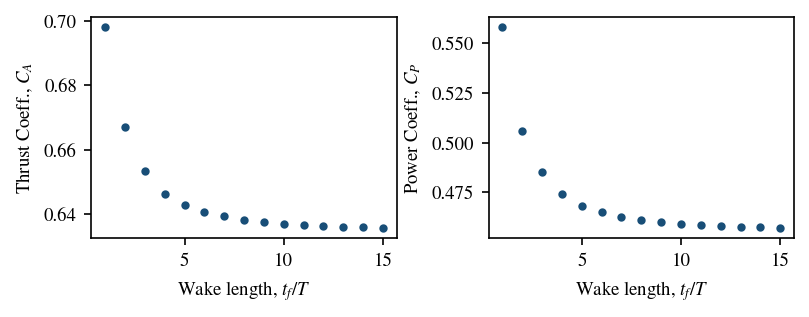

In [ ]:
nb    = 3       # number of blades
ncp   = 22      # number of panels (control points) in each blade
R     = 50      # radius of the rotor, m
Rroot = 10      # root radius of the rotor, m
TSR   = 8       # tip speed ratio
a     = 1/3     # induction factor
dt    = 0.1     # time-steep for vortex sheeding, s
ndt   = 400     #  number of time-steps for wake
Uwind = 10      # x-direction wake speed, m/s
airfoil = './Resources/DU95W180.csv'
ChordCoefs = [3,   1, 1]    # ChordCoefs = [ca, cb, cc], # Chord = ca*(1 - cb*(r/R) ) + cc
TwistCoefs = [-14, 1, 2]    # TwistCoefs = [ta, tb, tc], # Twist = ta*(1 - tb*(r/R) ) + tc
Omega = TSR*Uwind/R         # Rotor's rotational speed, rad/s

normGamma = Uwind**2 * np.pi / ( Omega * nb)
forceNorm = 0.5 * Uwind**2 * (np.pi * R ** 2)

## Seed control points along radius ================= #
method = 'cosine' # 'linear' or 'cosine'
r, dr = createRadius(Rroot, R, ncp, method) # pointing to the control points


## How many grid-points there are in 1 rotation
rotationPeriod = ( 1 / (Omega / (2*np.pi) ) )
npointsPerT  = rotationPeriod/dt
numberOfRotations = np.linspace(1,15,num=15)


# Power/Thrust coefficient for increasing number of rotations
CP = np.zeros_like(numberOfRotations)
CA = np.zeros_like(numberOfRotations)

#fig, axs = plt.subplots(1, 2, figsize=(14*cm2in, 5*cm2in), dpi=150)
#plt.subplots_adjust(left=0.1, bottom=0.2, right=0.95, top=0.95, wspace=0.3)

print('=========================================')

for i, numRot in enumerate(numberOfRotations):

    ndt =  int( numRot * npointsPerT ) # increase number of data points
    print('Number of time-steps: %0.0f' % ndt )
    
    bladepanels, trailingVortexes, mySolutionVector = construstGeometry(ChordCoefs, TwistCoefs, r, dr, dt, Uwind*(1-a), -Omega, nb, ncp, ndt)
     
    LLM = liftingLineSolver(mySolutionVector, bladepanels, trailingVortexes, Uwind, Omega, R, airfoil)
 
    #axs[0].plot(LLM.r_R, LLM.Gamma/normGamma, 'o', markersize=3., color=myColors[i], label=r'$t_f/T=%0.0f$' % numRot )
    #axs[1].plot(LLM.r_R, LLM.a, 'o', markersize=3., color=myColors[i] )

    
    CA[i] = np.sum( LLM.Fnorm[0:ncp] * dr  ) / forceNorm  * nb
    CP[i] = np.sum( LLM.Ftan[0:ncp]  * dr * (LLM.r_R[0:ncp] * Omega * R) ) / (forceNorm * Uwind) * nb
    

print('=========================================')

axs[0].set_xlabel(r'$r/R$')
axs[0].set_ylabel(r'Ciculation, $ \Gamma^\star $')
axs[0].legend(ncols=2, loc='center', bbox_to_anchor=(0.5, 0.2), frameon=False)

axs[1].set_ylabel(r'Axial induction, $a$')
axs[1].set_xlabel(r'$r/R$')


plt.savefig("./Images/LLM_Effects_of_NumberOfPeriods.pdf", dpi=300)


##  Show results ========================= #
fig, axs = plt.subplots(1, 2, figsize=(14*cm2in, 5*cm2in), dpi=150)
plt.subplots_adjust(left=0.1, bottom=0.2, right=0.95, top=0.95, wspace=0.3)

axs[0].plot(numberOfRotations, CA, 'o', markersize=3., color=myColors[1], label='LLM')
axs[0].set_ylabel(r'Thrust Coeff., $C_A$')
axs[0].set_xlabel(r'Wake length, $t_f/T$')

axs[1].plot(numberOfRotations, CP, 'o', markersize=3., color=myColors[1], label='LLM')
axs[1].set_ylabel(r'Power Coeff., $C_P$')
axs[1].set_xlabel(r'Wake length, $t_f/T$')

plt.savefig("./Images/LLM_Convergence_vs_WakeLength"+fig_format, dpi=300)


## Compare cosine vs. linear distribuitions ##

Done.
Done.


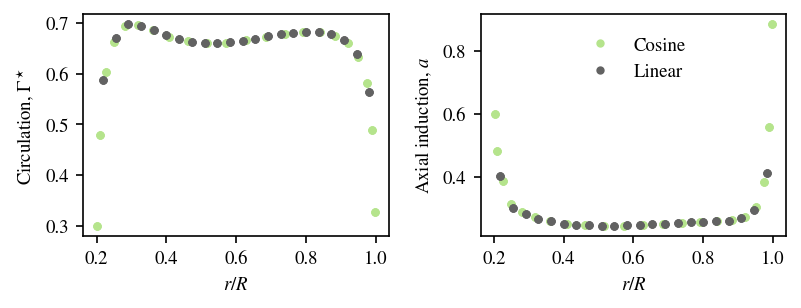

In [ ]:
nb    = 3       # number of blades
ncp   = 22      # number of panels (control points) in each blade
R     = 50      # radius of the rotor, m
Rroot = 10      # root radius of the rotor, m
TSR  = 8       # tip speed ratio
a     = 1/3     # induction factor
dt   = 0.1     # time-steep for vortex sheeding, s
ndt   = 400    #  number of time-steps for wake
Uwind = 10      # x-direction wake speed, m/s
airfoil = './Resources/DU95W180.csv'
ChordCoefs = [3,   1, 1]    # ChordCoefs = [ca, cb, cc], # Chord = ca*(1 - cb*(r/R) ) + cc
TwistCoefs = [-14, 1, 2]    # TwistCoefs = [ta, tb, tc], # Twist = ta*(1 - tb*(r/R) ) + tc
Omega = TSR*Uwind/R      # Rotor's rotational speed, rad/s
normGamma = Uwind**2 * np.pi / ( Omega * nb)


fig, axs = plt.subplots(1, 2, figsize=(14*cm2in, 5*cm2in), dpi=150)
plt.subplots_adjust(left=0.1, bottom=0.2, right=0.95, top=0.95, wspace=0.3)

## Cosine distrbuition ================= #

method = 'cosine' # 'linear' or 'cosine'
r, dr = createRadius(Rroot, R, ncp, method) # pointing to the control points

bladepanels, trailingVortexes, mySolutionVector = construstGeometry(ChordCoefs, TwistCoefs, r, dr, dt, Uwind*(1-a), -Omega, nb, ncp, ndt)
LLM = liftingLineSolver(mySolutionVector, bladepanels, trailingVortexes, Uwind, Omega, R, airfoil)

axs[0].plot(LLM.r_R, LLM.Gamma/normGamma, 'o', markersize=3., color=myColors[5] )
axs[1].plot(LLM.r_R, LLM.a, 'o', markersize=3., color=myColors[5], label=r'Cosine')

    
## Linear distrbuition ================= #

method = 'linear' # 'linear' or 'cosine'
r, dr = createRadius(Rroot, R, ncp, method) # pointing to the control points

bladepanels, trailingVortexes, mySolutionVector = construstGeometry(ChordCoefs, TwistCoefs, r, dr, dt, Uwind*(1-a), -Omega, nb, ncp, ndt)
LLM = liftingLineSolver(mySolutionVector, bladepanels, trailingVortexes, Uwind, Omega, R, airfoil)

axs[0].plot(LLM.r_R, LLM.Gamma/normGamma, 'o', markersize=3., color=myColors[0] )
axs[1].plot(LLM.r_R, LLM.a, 'o', markersize=3., color=myColors[0], label=r'Linear')


## Fix the plot

axs[0].set_xlabel(r'$r/R$')
axs[0].set_ylabel(r'Circulation, $ \Gamma^\star $')

axs[1].set_ylabel(r'Axial induction, $a$')
axs[1].set_xlabel(r'$r/R$')
axs[1].legend(ncols=1, loc='center', bbox_to_anchor=(0.5, 0.80), frameon=False)


plt.savefig("./Images/LLM_Effects_of_NodeDistribuition"+fig_format, dpi=300)

## Grid-independence analysis: number of blade sections ##

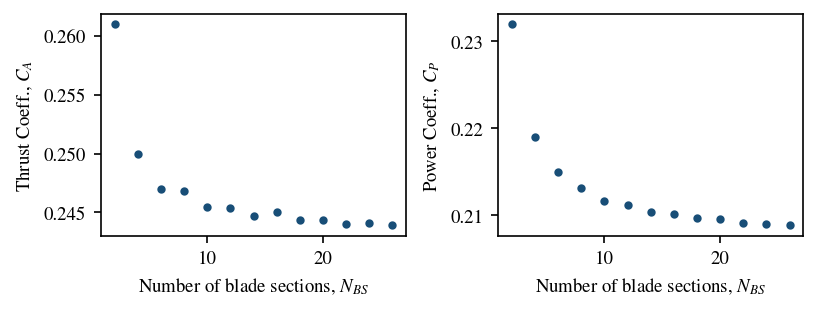

In [ ]:
##  Show results ========================= #
SimData = pd.read_csv('./SingleBladeData.csv', sep=',')


fig, axs = plt.subplots(1, 2, figsize=(14*cm2in, 5*cm2in), dpi=150)
plt.subplots_adjust(left=0.1, bottom=0.2, right=0.95, top=0.95, wspace=0.3)

axs[0].plot(SimData.ncp, SimData.CT, 'o', markersize=3., color=myColors[1], label='LLM')
axs[0].set_ylabel(r'Thrust Coeff., $C_A$')
axs[0].set_xlabel(r'Number of blade sections, $N_{BS}$')

axs[1].plot(SimData.ncp, SimData.CP, 'o', markersize=3., color=myColors[1], label='LLM')
axs[1].set_ylabel(r'Power Coeff., $C_P$')
axs[1].set_xlabel(r'Number of blade sections, $N_{BS}$')


plt.savefig("./Images/LLM_Convergence_vs_Ncp"+fig_format, dpi=300)